# 🛡️ DeepGuard — Final Training Notebook (Isolation Forest + Autoencoder + XGBoost + SHAP)

One notebook that trains **every model in the project proposal**, evaluates all of them with the **same full metric set**, and **saves all figures, tables, models and reports** into one folder (and a zip).

| Component | Role |
|---|---|
| **Isolation Forest** (scikit-learn) | unsupervised anomaly score — fitted on train rows, **no labels used** |
| **Autoencoder** (PyTorch) | learns what a *normal* transaction looks like (normal train rows only); reconstruction error + 8-dim code |
| **XGBoost** (GPU) | supervised detector on past-only behavioural features (+ AE / IF scores as extra features) |
| **SHAP** | explains *why* a transaction is flagged |

**Models compared on the same untouched test period (7 variants):**
`Isolation Forest alone` · `Autoencoder alone` · `Unsupervised AE+IF` · `XGBoost (base)` · `XGBoost + AE` · `XGBoost + IF` · `XGBoost + AE + IF`

**Metrics reported for every variant:** Accuracy, Balanced accuracy, Precision, Recall (sensitivity), Specificity, F1, F2, ROC-AUC, **Average Precision (PR-AUC)**, MCC, Cohen's kappa, Brier score, Log-loss, FPR, FNR, Precision@k, full confusion matrix, **classification report**, bootstrap 95 % CI.

**Rules (no leakage):** features use only past rows · time-based 60/20/20 split · model **and** threshold chosen on **validation only** · test set touched once.

> ⚠️ **Read this once:** with only **0.1–0.18 % fraud**, *Accuracy* is ≈ 99.9 % even for a model that finds nothing. Use **AP, ROC-AUC, Precision, Recall and F1** to judge the model — that is why all of them are reported.

> Runtime: High-RAM + **T4 GPU** ≈ 40–55 min. Everything is saved to `deepguard_results/` and zipped at the end.

In [ ]:
import os, time, json, joblib, shutil, warnings, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
!pip install -q xgboost shap
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve, precision_recall_curve, f1_score, fbeta_score,
                             precision_score, recall_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef,
                             cohen_kappa_score, brier_score_loss, log_loss, classification_report, confusion_matrix)
from sklearn.ensemble import IsolationForest
from sklearn.calibration import calibration_curve
import xgboost as xgb, torch, torch.nn as nn

SMOKE = False                                   # (developer switch for a tiny test run — keep False on Colab)
ROOT  = os.environ.get('DG_ROOT', '/content')
OUT   = f'{ROOT}/deepguard_results'
FIG, TAB, MOD = f'{OUT}/figures', f'{OUT}/tables', f'{OUT}/models'
for d in (FIG, TAB, MOD): os.makedirs(d, exist_ok=True)
SAVED = []
XGB_DEVICE = 'cuda' if shutil.which('nvidia-smi') else 'cpu'
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED = 42; np.random.seed(SEED); torch.manual_seed(SEED)

plt.rcParams.update({'figure.facecolor':'white','axes.facecolor':'white','axes.grid':True,'grid.alpha':.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10,'axes.titleweight':'bold'})
COLORS = {'Isolation Forest alone':'#8c564b','Autoencoder alone':'#7f7f7f','Unsupervised AE+IF':'#bcbd22',
          'XGBoost (base)':'#1f77b4','XGBoost + AE':'#ff7f0e','XGBoost + IF':'#2ca02c','XGBoost + AE + IF':'#d62728'}
def save_fig(name):
    plt.tight_layout(); p = f'{FIG}/{name}.png'
    plt.savefig(p, dpi=160, bbox_inches='tight', facecolor='white'); SAVED.append(p); plt.show()
def save_table(df_, name, index=True):
    p = f'{TAB}/{name}.csv'; df_.to_csv(p, index=index); SAVED.append(p)
print("XGBoost", xgb.__version__, "| torch", torch.__version__, "| devices:", XGB_DEVICE, DEV, "| SMOKE =", SMOKE)

XGBoost 3.4.1 | torch 2.11.0+cu130 | devices: cuda cuda | SMOKE = False


## 📥 Step 1 — Load the FULL HI-Small file

In [ ]:
DATA_PATH = f'{ROOT}/data/HI-Small_Trans.csv'
ALT_PATH  = '/content/drive/MyDrive/fyp-projects/final_model/HI-Small_Trans.csv'   # 🔧 your Drive copy, if you have one
if SMOKE: DATA_PATH = os.environ['DG_SYNTH']
if not os.path.exists(DATA_PATH) and os.path.exists(ALT_PATH):
    DATA_PATH = ALT_PATH
if not os.path.exists(DATA_PATH):
    os.makedirs(f'{ROOT}/data', exist_ok=True)
    if not os.path.exists('/root/.kaggle/kaggle.json'):
        from google.colab import files
        up = files.upload(); os.makedirs('/root/.kaggle', exist_ok=True)
        open('/root/.kaggle/kaggle.json','wb').write(up['kaggle.json']); os.chmod('/root/.kaggle/kaggle.json', 0o600)
    !kaggle datasets download -d ealtman2019/ibm-transactions-for-anti-money-laundering-aml -f HI-Small_Trans.csv -p /content/data
    if os.path.exists('/content/data/HI-Small_Trans.csv.zip'):
        !unzip -o /content/data/HI-Small_Trans.csv.zip -d /content/data
    DATA_PATH = f'{ROOT}/data/HI-Small_Trans.csv'

names = ['Timestamp','From_Bank','Sender','To_Bank','Receiver','Amount_Received','Receiving_Currency',
         'Amount_Paid','Payment_Currency','Payment_Format','Is_Laundering']
df = pd.read_csv(DATA_PATH, header=0, names=names,
                 dtype={'From_Bank':'int32','To_Bank':'int32','Amount_Received':'float64','Amount_Paid':'float64','Is_Laundering':'int8'})
df['Timestamp'] = pd.to_datetime(df['Timestamp'], format='%Y/%m/%d %H:%M')
if not SMOKE: assert len(df) > 5_000_000, f"File incomplete: {len(df):,} rows"
df = df.sort_values('Timestamp', kind='stable').reset_index(drop=True)
y_all = df['Is_Laundering'].to_numpy()
print(f"{len(df):,} rows | fraud {int(y_all.sum()):,} ({y_all.mean()*100:.3f}%)")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml
License(s): Community Data License Agreement - Sharing - Version 1.0
100% 454M/454M [00:07<00:00, 65.6MB/s]

5,078,345 rows | fraud 5,177 (0.102%)


## ⚙️ Step 2 — Past-only behavioural features (35) + time-window features (12)

In [ ]:
def build_features(df):
    '''df must be sorted by time (stable). EVERY feature uses only rows EARLIER in the sorted order (plus the row itself)
    -> no future leakage; train/val/test rows get features computed in exactly the same way.'''
    n = len(df)
    allacc = pd.concat([df['Sender'], df['Receiver']], ignore_index=True)
    codes, _ = pd.factorize(allacc)
    sid = codes[:n].astype('int64'); rid = codes[n:].astype('int64')
    t = (df['Timestamp'] - df['Timestamp'].min()).dt.total_seconds().to_numpy()
    ap = df['Amount_Paid'].to_numpy('float64'); ar = df['Amount_Received'].to_numpy('float64')

    w = pd.DataFrame({'sid': sid, 'rid': rid, 't': t, 'ap': ap, 'ar': ar})
    w['hb'] = (t // 3600).astype('int64'); w['db'] = (t // 86400).astype('int64')
    F = pd.DataFrame(index=w.index)

    # ---- basic row features ----
    F['Log_Amount_Paid']  = np.log1p(ap)
    F['Log_Amount_Recv']  = np.log1p(ar)
    F['Log_Amount_Ratio'] = F['Log_Amount_Paid'] - F['Log_Amount_Recv']
    F['Is_Round_Amount']  = ((ap % 1000) == 0).astype('int8')
    hour = df['Timestamp'].dt.hour.to_numpy()
    F['Hour'] = hour; F['DayOfWeek'] = df['Timestamp'].dt.dayofweek.to_numpy()
    F['Is_Night'] = ((hour >= 22) | (hour <= 5)).astype('int8')
    F['Is_Self_Transfer']  = (sid == rid).astype('int8')
    F['Is_Cross_Bank']     = (df['From_Bank'].to_numpy() != df['To_Bank'].to_numpy()).astype('int8')
    F['Is_Cross_Currency'] = (df['Receiving_Currency'].astype(str).to_numpy() != df['Payment_Currency'].astype(str).to_numpy()).astype('int8')
    for col, name in [('Payment_Format','Payment_Format_enc'), ('Payment_Currency','Payment_Currency_enc'), ('Receiving_Currency','Receiving_Currency_enc')]:
        F[name] = pd.factorize(df[col].astype(str), sort=True)[0].astype('int8')

    # ---- sender history (strictly earlier rows) ----
    gs = w.groupby('sid')
    F['S_out_n']     = gs.cumcount()
    prev_sum         = gs['ap'].cumsum() - w['ap']
    avg_prev         = prev_sum / F['S_out_n'].where(F['S_out_n'] > 0)
    F['S_amt_vs_avg'] = F['Log_Amount_Paid'] - np.log1p(avg_prev)
    F['S_dt_prev']   = gs['t'].diff()
    pair_n           = w.groupby(['sid', 'rid']).cumcount()
    F['Pair_n']      = pair_n
    new_pair         = (pair_n == 0).astype('int64')
    F['S_uniq_recv'] = new_pair.groupby(w['sid']).cumsum() - new_pair
    F['S_new_recv_rate'] = F['S_uniq_recv'] / (F['S_out_n'] + 1)
    F['S_same_hour'] = w.groupby(['sid', 'hb']).cumcount()
    F['S_same_day']  = w.groupby(['sid', 'db']).cumcount()
    F['S_same_amt']  = w.groupby(['sid', 'ap']).cumcount()

    # ---- receiver history ----
    gr = w.groupby('rid')
    F['R_in_n']      = gr.cumcount()
    F['R_dt_prev']   = gr['t'].diff()
    F['R_uniq_send'] = new_pair.groupby(w['rid']).cumsum() - new_pair
    F['R_same_hour'] = w.groupby(['rid', 'hb']).cumcount()
    F['R_same_day']  = w.groupby(['rid', 'db']).cumcount()
    r_prev_sum       = gr['ar'].cumsum() - w['ar']
    F['R_amt_vs_avg'] = F['Log_Amount_Recv'] - np.log1p(r_prev_sum / F['R_in_n'].where(F['R_in_n'] > 0))

    # ---- in/out behaviour of each account (pass-through / mule patterns) ----
    ev_acct = np.concatenate([sid, rid]); ev_pos = np.arange(2 * n)
    ev_ord  = np.concatenate([np.arange(n), np.arange(n)])
    ev_in   = np.concatenate([np.zeros(n, 'int8'), np.ones(n, 'int8')])
    ev_amt  = np.concatenate([ap, ar])
    order   = np.lexsort((ev_in, ev_ord))
    E = pd.DataFrame({'a': ev_acct[order], 'isin': ev_in[order].astype('int64'), 'amt': ev_amt[order], 'pos': ev_pos[order]})
    E['in_amt']  = E['amt'] * E['isin']
    E['out_amt'] = E['amt'] * (1 - E['isin'])
    E['isout']   = 1 - E['isin']
    ge = E.groupby('a')
    cum_in_amt  = ge['in_amt'].cumsum()  - E['in_amt']
    cum_out_amt = ge['out_amt'].cumsum() - E['out_amt']
    cum_in_n    = ge['isin'].cumsum()    - E['isin']
    cum_out_n   = ge['isout'].cumsum()   - E['isout']
    res = np.zeros((4, 2 * n))
    res[0, E['pos'].to_numpy()] = cum_in_amt.to_numpy()
    res[1, E['pos'].to_numpy()] = cum_out_amt.to_numpy()
    res[2, E['pos'].to_numpy()] = cum_in_n.to_numpy()
    res[3, E['pos'].to_numpy()] = cum_out_n.to_numpy()
    F['S_prior_in_n']     = res[2, :n]
    F['S_prior_in_amt']   = np.log1p(res[0, :n])
    F['S_passthru']       = F['Log_Amount_Paid'] - F['S_prior_in_amt']
    selfm = (sid == rid)
    F['R_prior_out_n']    = res[3, n:] - selfm
    F['R_prior_out_amt']  = np.log1p(np.maximum(res[1, n:] - ap * selfm, 0))
    F['R_prior_in_amt']   = np.log1p(res[0, n:])
    F['R_out_in_ratio']   = F['R_prior_out_amt'] - F['R_prior_in_amt']
    return F.astype('float32')

def window_features(df):
    '''Past-only time-window activity (last 1h / 24h). Own-role windows use position order (same as cumcount);
    cross-role windows (sender's recent INCOMING, receiver's recent OUTGOING) use strictly earlier timestamps.'''
    n = len(df)
    allacc = pd.concat([df['Sender'], df['Receiver']], ignore_index=True)
    codes, _ = pd.factorize(allacc)
    sid = codes[:n].astype('int64'); rid = codes[n:].astype('int64')
    t = (df['Timestamp'] - df['Timestamp'].min()).dt.total_seconds().to_numpy().astype('int64')
    ap = df['Amount_Paid'].to_numpy('float64'); ar = df['Amount_Received'].to_numpy('float64')
    K = np.int64(10**8); out = {}
    def own(acct, amt, tag):
        order = np.lexsort((np.arange(n), t, acct))
        key = acct[order] * K + t[order]
        cs = np.concatenate([[0.0], np.cumsum(amt[order])]); pos = np.arange(n)
        for W, nm in [(3600, '1h'), (86400, '24h')]:
            lo = np.searchsorted(key, key - W, side='left')
            c = np.empty(n); c[order] = pos - lo; out[f'{tag}_cnt_{nm}'] = c
            if nm == '24h':
                a = np.empty(n); a[order] = cs[pos] - cs[lo]; out[f'{tag}_amt_24h'] = np.log1p(np.maximum(a, 0))
    def cross(ev_acct, ev_amt, q_acct, tag):
        order = np.lexsort((t, ev_acct))
        ek = ev_acct[order] * K + t[order]
        cs = np.concatenate([[0.0], np.cumsum(ev_amt[order])])
        qk = q_acct * K + t
        hi = np.searchsorted(ek, qk, side='left')
        for W, nm in [(3600, '1h'), (86400, '24h')]:
            lo = np.searchsorted(ek, qk - W, side='left')
            out[f'{tag}_cnt_{nm}'] = (hi - lo).astype('float64')
            if nm == '24h': out[f'{tag}_amt_24h'] = np.log1p(np.maximum(cs[hi] - cs[lo], 0))
    own(sid, ap, 'S_out'); own(rid, ar, 'R_in')
    cross(rid, ar, sid, 'S_in'); cross(sid, ap, rid, 'R_out')
    return pd.DataFrame(out).astype('float32')

In [ ]:
t0 = time.time()
F = pd.concat([build_features(df), window_features(df)], axis=1)
feature_cols = list(F.columns)
print(f"✅ {len(feature_cols)} features in {time.time()-t0:.0f}s | {F.memory_usage().sum()/1024**3:.2f} GB")
HEAD = min(20_000, len(df))                         # kept only for the correctness check in Step 2b
df_head = df.iloc[:HEAD].copy(); F_head = F.iloc[:HEAD].copy()
X_all = F.to_numpy(dtype='float32'); del F, df
n = len(y_all); i_tr, i_va = int(n*0.6), int(n*0.8)
X_tr, y_tr = X_all[:i_tr],     y_all[:i_tr]
X_va, y_va = X_all[i_tr:i_va], y_all[i_tr:i_va]
X_te, y_te = X_all[i_va:],     y_all[i_va:]
split_tbl = pd.DataFrame({'Rows':[len(y_tr),len(y_va),len(y_te)], 'Fraud':[int(y_tr.sum()),int(y_va.sum()),int(y_te.sum())],
                          'Fraud_%':[y_tr.mean()*100,y_va.mean()*100,y_te.mean()*100]}, index=['Train (60%)','Validation (20%)','Test (20%)'])
display(split_tbl.round(4)); save_table(split_tbl, 'T00_data_split')
if not SMOKE: assert y_va.sum() >= 200 and y_te.sum() >= 200

✅ 47 features in 42s | 0.89 GB


,Rows,Fraud,Fraud_%
Train (60%),3047007,2298,0.0754
Validation (20%),1015669,1082,0.1065
Test (20%),1015669,1797,0.1769


## ✅ Step 2b — Feature-correctness check (no future leakage)
Two proofs, both executed in code:
1. **Prefix-invariance** — features of the first rows computed on *only* that prefix must equal the features computed on the *whole* file. If any feature looked into the future, this would fail.
2. **Brute-force reference** — a few features recomputed with plain Python loops on random rows and compared to the fast vectorised version.

In [ ]:
# 1) prefix-invariance (categorical *_enc columns excluded: their integer codes depend on which labels are present)
Fp = pd.concat([build_features(df_head), window_features(df_head)], axis=1)
cmp_cols = [c for c in feature_cols if not c.endswith('_enc')]
bad = [c for c in cmp_cols if not np.allclose(Fp[c].to_numpy(), F_head[c].to_numpy(), rtol=1e-4, atol=1e-3, equal_nan=True)]
print(f"prefix-invariance on first {HEAD:,} rows: {len(cmp_cols)-len(bad)}/{len(cmp_cols)} features identical", "✅" if not bad else f"❌ differ: {bad}")

# 2) brute-force reference on random rows
S = df_head['Sender'].to_numpy(); R = df_head['Receiver'].to_numpy()
T = ((df_head['Timestamp'] - df_head['Timestamp'].min()).dt.total_seconds()).to_numpy().astype('int64')
AP = df_head['Amount_Paid'].to_numpy('float64')
rng_c = np.random.default_rng(7); rows = rng_c.choice(np.arange(200, HEAD), size=min(150, HEAD-200), replace=False)
checks = {k: [] for k in ['S_out_n','Pair_n','S_uniq_recv','S_out_cnt_1h','S_out_amt_24h','S_in_cnt_24h','R_out_cnt_1h']}
for i in rows:
    s, r, ti = S[i], R[i], T[i]
    same_s = (S[:i] == s)
    checks['S_out_n'].append((same_s.sum(), F_head['S_out_n'].iloc[i]))
    checks['Pair_n'].append(((same_s & (R[:i] == r)).sum(), F_head['Pair_n'].iloc[i]))
    checks['S_uniq_recv'].append((len(set(R[:i][same_s])), F_head['S_uniq_recv'].iloc[i]))
    checks['S_out_cnt_1h'].append(((same_s & (T[:i] >= ti-3600)).sum(), F_head['S_out_cnt_1h'].iloc[i]))
    checks['S_out_amt_24h'].append((np.log1p(AP[:i][same_s & (T[:i] >= ti-86400)].sum()), F_head['S_out_amt_24h'].iloc[i]))
    checks['S_in_cnt_24h'].append((((R == s) & (T >= ti-86400) & (T < ti)).sum(), F_head['S_in_cnt_24h'].iloc[i]))
    checks['R_out_cnt_1h'].append((((S == r) & (T >= ti-3600) & (T < ti)).sum(), F_head['R_out_cnt_1h'].iloc[i]))
rows_out = []
for k, v in checks.items():
    a = np.array(v, dtype='float64'); ok = np.allclose(a[:,0], a[:,1], rtol=1e-4, atol=1e-3)
    rows_out.append({'Feature': k, 'Rows_checked': len(a), 'Max_abs_diff': float(np.abs(a[:,0]-a[:,1]).max()), 'Match': '✅' if ok else '❌'})
chk = pd.DataFrame(rows_out); display(chk); save_table(chk, 'T01_feature_bruteforce_check', index=False)
del df_head, F_head, Fp

prefix-invariance on first 20,000 rows: 44/44 features identical ✅


,Feature,Rows_checked,Max_abs_diff,Match
0,S_out_n,150,0.000000e+00,✅
1,Pair_n,150,0.000000e+00,✅
2,S_uniq_recv,150,0.000000e+00,✅
3,S_out_cnt_1h,150,0.000000e+00,✅
4,S_out_amt_24h,150,7.509067e-07,✅
5,S_in_cnt_24h,150,0.000000e+00,✅
6,R_out_cnt_1h,150,0.000000e+00,✅


## 🧠 Step 3 — Autoencoder (trained on NORMAL train transactions only)
Reconstruction error = anomaly score; the 8-dim bottleneck is a compact "behaviour embedding". Preprocessing (signed-log → median-fill → standardise → clip) is **fitted on normal train rows only**.

epoch  1/12  train MSE = 0.2650  val-normal MSE = 0.1658  (3s)
epoch  2/12  train MSE = 0.1317  val-normal MSE = 0.1496  (5s)
epoch  3/12  train MSE = 0.1169  val-normal MSE = 0.1379  (8s)
epoch  4/12  train MSE = 0.1072  val-normal MSE = 0.1286  (13s)
epoch  5/12  train MSE = 0.1010  val-normal MSE = 0.1216  (16s)
epoch  6/12  train MSE = 0.0964  val-normal MSE = 0.1186  (19s)
epoch  7/12  train MSE = 0.0931  val-normal MSE = 0.1145  (21s)
epoch  8/12  train MSE = 0.0907  val-normal MSE = 0.1121  (23s)
epoch  9/12  train MSE = 0.0885  val-normal MSE = 0.1101  (26s)
epoch 10/12  train MSE = 0.0867  val-normal MSE = 0.1078  (28s)
epoch 11/12  train MSE = 0.0851  val-normal MSE = 0.1069  (30s)
epoch 12/12  train MSE = 0.0837  val-normal MSE = 0.1049  (33s)


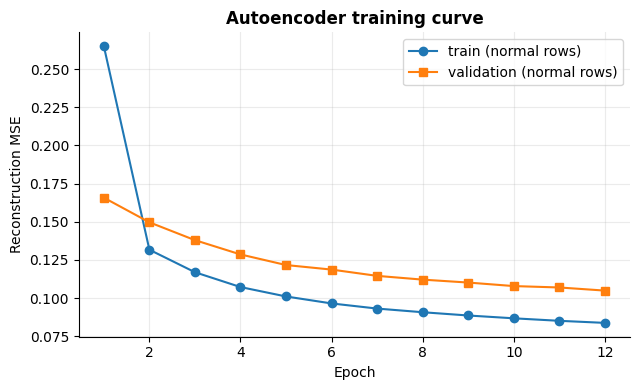


mean AE error of NORMAL rows:  train 0.0833 | validation 0.1083 | test 0.1585   (test/train = 1.90x)
→ The error of normal rows RISES over time: behaviour drifts as accounts accumulate history (concept drift).
  This is NOT leakage. Note: AE features of TRAIN rows are in-sample (slightly optimistic for XGBoost); the validation/test
  AE features are out-of-sample, and only those are used for model choice and for every reported result.


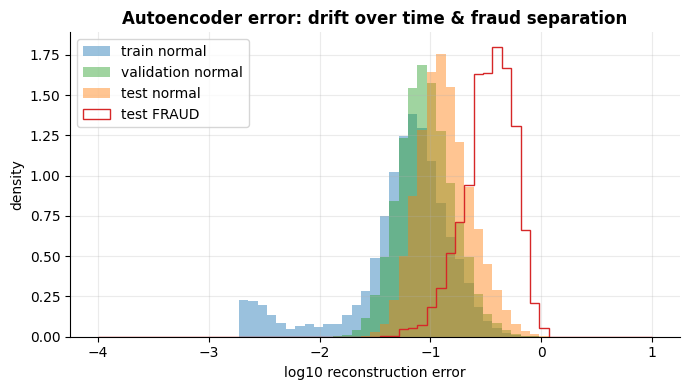

AE alone → val AP 0.0351 | test AP 0.0164 | test ROC-AUC 0.8807


In [ ]:
def slog(X): return np.sign(X) * np.log1p(np.abs(X))
_norm = X_tr[y_tr == 0]
_Z = slog(_norm)
AE_MED = np.nanmedian(_Z, axis=0).astype('float32')
_Z = np.where(np.isnan(_Z), AE_MED, _Z)
AE_MU = _Z.mean(0).astype('float32'); AE_SD = _Z.std(0).astype('float32'); AE_SD[AE_SD < 1e-6] = 1.0
def ae_prep(X):
    Z = slog(X); Z = np.where(np.isnan(Z), AE_MED, Z)
    return np.clip((Z - AE_MU) / AE_SD, -6, 6).astype('float32')
Z_norm = ae_prep(_norm); del _norm, _Z
D = Z_norm.shape[1]

class AE(nn.Module):
    def __init__(s, d, z=8):
        super().__init__()
        s.enc = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, z))
        s.dec = nn.Sequential(nn.Linear(z, 32), nn.ReLU(), nn.Linear(32, 64), nn.ReLU(), nn.Linear(64, d))
    def forward(s, x):
        z = s.enc(x); return s.dec(z), z

ae = AE(D).to(DEV); opt = torch.optim.Adam(ae.parameters(), lr=1e-3); lossf = nn.MSELoss()
Zt = torch.from_numpy(Z_norm); EPOCHS, BS = (2 if SMOKE else 12), 4096
Zv = torch.from_numpy(ae_prep(X_va[y_va == 0][:200_000]))          # validation-normal rows: monitor only, never used to train
hist = []; t0 = time.time()
for ep in range(EPOCHS):
    ae.train(); perm = torch.randperm(len(Zt)); tot = 0.0
    for i in range(0, len(Zt), BS):
        xb = Zt[perm[i:i+BS]].to(DEV)
        out, _ = ae(xb); loss = lossf(out, xb)
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(xb)
    ae.eval()
    with torch.no_grad(): vl = lossf(ae(Zv.to(DEV))[0], Zv.to(DEV)).item()
    hist.append((ep+1, tot/len(Zt), vl))
    print(f"epoch {ep+1:2d}/{EPOCHS}  train MSE = {tot/len(Zt):.4f}  val-normal MSE = {vl:.4f}  ({time.time()-t0:.0f}s)")
del Zt, Z_norm
hist = pd.DataFrame(hist, columns=['epoch','train_mse','val_normal_mse']); save_table(hist, 'T02_autoencoder_training_history', index=False)
plt.figure(figsize=(6.5,4)); plt.plot(hist.epoch, hist.train_mse, 'o-', label='train (normal rows)'); plt.plot(hist.epoch, hist.val_normal_mse, 's-', label='validation (normal rows)')
plt.xlabel('Epoch'); plt.ylabel('Reconstruction MSE'); plt.title('Autoencoder training curve'); plt.legend(); save_fig('fig01_autoencoder_training_loss')

@torch.no_grad()
def ae_out(X, bs=200_000):
    ae.eval(); errs, zs = [], []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(ae_prep(X[i:i+bs])).to(DEV)
        out, z = ae(xb); errs.append(((out - xb) ** 2).mean(1).cpu().numpy()); zs.append(z.cpu().numpy())
    return np.concatenate(errs).astype('float32'), np.vstack(zs).astype('float32')
err_tr, z_tr = ae_out(X_tr); err_va, z_va = ae_out(X_va); err_te, z_te = ae_out(X_te)

m_tr, m_va, m_te = err_tr[y_tr==0].mean(), err_va[y_va==0].mean(), err_te[y_te==0].mean()
print(f"\nmean AE error of NORMAL rows:  train {m_tr:.4f} | validation {m_va:.4f} | test {m_te:.4f}   (test/train = {m_te/m_tr:.2f}x)")
print("→ The error of normal rows RISES over time: behaviour drifts as accounts accumulate history (concept drift).")
print("  This is NOT leakage. Note: AE features of TRAIN rows are in-sample (slightly optimistic for XGBoost); the validation/test")
print("  AE features are out-of-sample, and only those are used for model choice and for every reported result.")
plt.figure(figsize=(7,4)); bins = np.linspace(-4, 1, 60)
for nm, e, yy, c in [('train normal', err_tr, y_tr, '#1f77b4'), ('validation normal', err_va, y_va, '#2ca02c'), ('test normal', err_te, y_te, '#ff7f0e')]:
    plt.hist(np.log10(e[yy==0]+1e-4), bins=bins, density=True, alpha=.45, label=nm, color=c)
plt.hist(np.log10(err_te[y_te==1]+1e-4), bins=bins, density=True, histtype='step', lw=2, color='#d62728', label='test FRAUD')
plt.xlabel('log10 reconstruction error'); plt.ylabel('density'); plt.title('Autoencoder error: drift over time & fraud separation'); plt.legend(); save_fig('fig02_autoencoder_error_drift')
print(f"AE alone → val AP {average_precision_score(y_va, err_va):.4f} | test AP {average_precision_score(y_te, err_te):.4f} | test ROC-AUC {roc_auc_score(y_te, err_te):.4f}")

## 🌲 Step 3b — Isolation Forest (unsupervised, labels never used)
Isolation Forest isolates unusual points with random splits — fewer splits needed ⇒ more anomalous. It is fitted on the (autoencoder-preprocessed) **training** rows **without labels**, then scores validation and test. Its score becomes both a stand-alone detector and an extra XGBoost feature (`IF_score`, higher = more anomalous).

Isolation Forest fitted + scored in 43s
IF alone → val AP 0.0018 | test AP 0.0026 | test ROC-AUC 0.6726


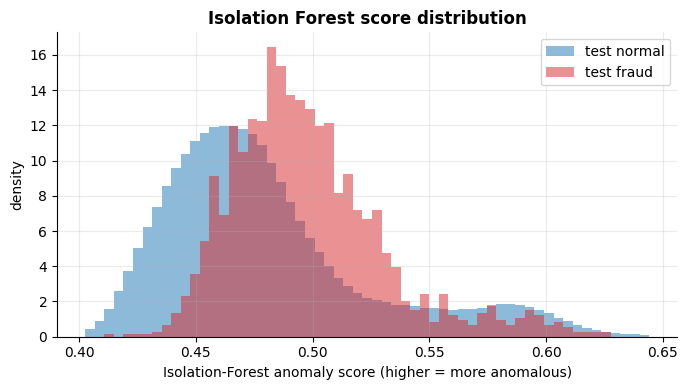

In [ ]:
t0 = time.time()
IF_TREES = 20 if SMOKE else 100
iforest = IsolationForest(n_estimators=IF_TREES, max_samples=512, contamination='auto', n_jobs=-1, random_state=SEED)
iforest.fit(ae_prep(X_tr))                                           # all train rows, NO labels
def if_score(X, bs=500_000):
    return np.concatenate([-iforest.score_samples(ae_prep(X[i:i+bs])) for i in range(0, len(X), bs)]).astype('float32')
if_tr, if_va, if_te = if_score(X_tr), if_score(X_va), if_score(X_te)
print(f"Isolation Forest fitted + scored in {time.time()-t0:.0f}s")
print(f"IF alone → val AP {average_precision_score(y_va, if_va):.4f} | test AP {average_precision_score(y_te, if_te):.4f} | test ROC-AUC {roc_auc_score(y_te, if_te):.4f}")
plt.figure(figsize=(7,4)); bins = np.linspace(np.percentile(if_te, .1), np.percentile(if_te, 99.9), 60)
plt.hist(if_te[y_te==0], bins=bins, density=True, alpha=.5, label='test normal'); plt.hist(if_te[y_te==1], bins=bins, density=True, alpha=.5, color='#d62728', label='test fraud')
plt.xlabel('Isolation-Forest anomaly score (higher = more anomalous)'); plt.ylabel('density'); plt.title('Isolation Forest score distribution'); plt.legend(); save_fig('fig03_isolation_forest_scores')

## 🧪 Step 4 — Train the four XGBoost variants
`base` (47 features) · `+AE` (+9) · `+IF` (+1) · `+AE+IF` (+10). Hyper-parameters are picked **per variant by validation AP only**.

In [ ]:
ae_cols = ['AE_err'] + [f'AE_z{i}' for i in range(8)]; if_cols = ['IF_score']
def stack(X, err, z, isf, use_ae, use_if):
    parts = [X] + ([err[:, None], z] if use_ae else []) + ([isf[:, None]] if use_if else [])
    return np.hstack(parts).astype('float32')
XGB_SPECS = {'XGBoost (base)': (False, False), 'XGBoost + AE': (True, False), 'XGBoost + IF': (False, True), 'XGBoost + AE + IF': (True, True)}
FE = {k: dict(tr=stack(X_tr, err_tr, z_tr, if_tr, *v), va=stack(X_va, err_va, z_va, if_va, *v), te=stack(X_te, err_te, z_te, if_te, *v),
              cols=feature_cols + (ae_cols if v[0] else []) + (if_cols if v[1] else [])) for k, v in XGB_SPECS.items()}

configs = [(10, 1, 1)] if SMOKE else [(10, 1, 1), (10, 20, 5), (12, 1, 1)]   # (max_depth, scale_pos_weight, min_child_weight)
N_EST = 60 if SMOKE else 1500
def fit_search(name):
    res = []
    for md_, spw, mcw in configs:
        t0 = time.time()
        m = xgb.XGBClassifier(n_estimators=N_EST, learning_rate=0.05, max_depth=md_, min_child_weight=mcw,
                              subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, scale_pos_weight=spw,
                              eval_metric='aucpr', early_stopping_rounds=100, tree_method='hist',
                              device=XGB_DEVICE, random_state=SEED, n_jobs=-1)
        m.fit(FE[name]['tr'], y_tr, eval_set=[(FE[name]['va'], y_va)], verbose=False)
        ap = average_precision_score(y_va, m.predict_proba(FE[name]['va'])[:, 1]); res.append((ap, (md_, spw, mcw), m))
        print(f"[{name:18s}] depth={md_:<2} spw={spw:<3} mcw={mcw:<2} → val AP={ap:.4f}  trees={m.best_iteration+1}  ({time.time()-t0:.0f}s)")
    return max(res, key=lambda r: r[0])
BEST = {k: fit_search(k) for k in XGB_SPECS}

[XGBoost (base)    ] depth=10 spw=1   mcw=1  → val AP=0.6313  trees=230  (38s)
[XGBoost (base)    ] depth=10 spw=20  mcw=5  → val AP=0.6350  trees=693  (60s)
[XGBoost (base)    ] depth=12 spw=1   mcw=1  → val AP=0.6333  trees=655  (65s)
[XGBoost + AE      ] depth=10 spw=1   mcw=1  → val AP=0.6297  trees=1143  (92s)
[XGBoost + AE      ] depth=10 spw=20  mcw=5  → val AP=0.6382  trees=901  (78s)
[XGBoost + AE      ] depth=12 spw=1   mcw=1  → val AP=0.6291  trees=1279  (106s)
[XGBoost + IF      ] depth=10 spw=1   mcw=1  → val AP=0.6309  trees=496  (54s)
[XGBoost + IF      ] depth=10 spw=20  mcw=5  → val AP=0.6369  trees=580  (57s)
[XGBoost + IF      ] depth=12 spw=1   mcw=1  → val AP=0.6309  trees=305  (46s)
[XGBoost + AE + IF ] depth=10 spw=1   mcw=1  → val AP=0.6302  trees=847  (79s)
[XGBoost + AE + IF ] depth=10 spw=20  mcw=5  → val AP=0.6343  trees=1113  (90s)
[XGBoost + AE + IF ] depth=12 spw=1   mcw=1  → val AP=0.6306  trees=963  (90s)


## 📈 Step 5 — Full metrics for EVERY variant (threshold = best-F1 on validation, test touched once)

In [ ]:
def pick_threshold(y, s):
    p, r, t = precision_recall_curve(y, s); f = 2*p[:-1]*r[:-1]/(p[:-1]+r[:-1]+1e-12)
    return float(t[np.argmax(f)]), float(f.max())

def full_metrics(name, y, s, thr, probabilistic):
    pred = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    k = int(y.sum()); topk = np.argsort(-s)[:k]
    d = dict(Model=name, Threshold=thr,
             Accuracy=accuracy_score(y, pred), Balanced_Accuracy=balanced_accuracy_score(y, pred),
             Precision=precision_score(y, pred, zero_division=0), Recall=recall_score(y, pred),
             Specificity=tn/(tn+fp), F1=f1_score(y, pred), F2=fbeta_score(y, pred, beta=2),
             ROC_AUC=roc_auc_score(y, s), AP_PR_AUC=average_precision_score(y, s),
             MCC=matthews_corrcoef(y, pred), Cohen_Kappa=cohen_kappa_score(y, pred),
             FPR=fp/(fp+tn), FNR=fn/(fn+tp), Precision_at_k=float(y[topk].mean()),
             Brier=brier_score_loss(y, s) if probabilistic else np.nan,
             Log_Loss=log_loss(y, np.clip(s, 1e-7, 1-1e-7)) if probabilistic else np.nan,
             TP=int(tp), FP=int(fp), FN=int(fn), TN=int(tn), Alerts=int(tp+fp))
    return d

# --- scores of every variant (val + test)
u_mu_e, u_sd_e = np.log(err_tr+1e-6).mean(), np.log(err_tr+1e-6).std(); u_mu_i, u_sd_i = if_tr.mean(), if_tr.std()
def uns(err, isf): return ((np.log(err+1e-6)-u_mu_e)/u_sd_e + (isf-u_mu_i)/u_sd_i).astype('float32')
V = {  # name -> dict(va, te, prob)
    'Isolation Forest alone': dict(va=if_va, te=if_te, prob=False),
    'Autoencoder alone':      dict(va=err_va, te=err_te, prob=False),
    'Unsupervised AE+IF':     dict(va=uns(err_va, if_va), te=uns(err_te, if_te), prob=False)}
for k in XGB_SPECS:
    m = BEST[k][2]; V[k] = dict(va=m.predict_proba(FE[k]['va'])[:, 1], te=m.predict_proba(FE[k]['te'])[:, 1], prob=True)
for k, v in V.items():
    v['thr'], v['val_f1'] = pick_threshold(y_va, v['va']); v['pred'] = (v['te'] >= v['thr']).astype(int)

full = pd.DataFrame([full_metrics(k, y_te, v['te'], v['thr'], v['prob']) | {'Val_AP': average_precision_score(y_va, v['va']), 'Val_F1': v['val_f1']} for k, v in V.items()]).set_index('Model')
save_table(full, 'T03_all_metrics_all_models_TEST')
compact = full[['Accuracy','Balanced_Accuracy','Precision','Recall','Specificity','F1','F2','ROC_AUC','AP_PR_AUC','MCC','Cohen_Kappa','Brier','Log_Loss','Precision_at_k']]
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
print("TEST-SET METRICS (all models, same held-out period):"); display(compact.round(4))
print("\nConfusion-matrix counts + alert volume:"); display(full[['Threshold','TP','FP','FN','TN','FPR','FNR','Alerts']].round(5))

# --- final model = best VALIDATION AP among the XGBoost variants (test never used to choose)
FINAL = max(XGB_SPECS, key=lambda k: BEST[k][0]); model = BEST[FINAL][2]; best_cfg = BEST[FINAL][1]
THRESH = V[FINAL]['thr']; s_te = V[FINAL]['te']; s_va = V[FINAL]['va']; pred = V[FINAL]['pred']
X_tr_f, X_va_f, X_te_f, cols_final = FE[FINAL]['tr'], FE[FINAL]['va'], FE[FINAL]['te'], FE[FINAL]['cols']
print(f"\n🏆 FINAL MODEL (chosen on validation AP): {FINAL}   config (depth, spw, mcw) = {best_cfg}   threshold = {THRESH:.4f}")

TEST-SET METRICS (all models, same held-out period):


,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,F2,ROC_AUC,AP_PR_AUC,MCC,Cohen_Kappa,Brier,Log_Loss,Precision_at_k
Model,,,,,,,,,,,,,,
Isolation Forest alone,0.5546,0.6522,0.0030,0.7501,0.5543,0.0059,0.0146,0.6726,0.0026,0.0257,0.0024,NaN,NaN,0.0006
Autoencoder alone,0.9849,0.5975,0.0263,0.2087,0.9863,0.0466,0.0873,0.8807,0.0164,0.0696,0.0436,NaN,NaN,0.0228
Unsupervised AE+IF,0.7789,0.7209,0.0053,0.6628,0.7791,0.0105,0.0256,0.7923,0.0041,0.0447,0.0070,NaN,NaN,0.0011
XGBoost (base),0.9992,0.8107,0.8950,0.6216,0.9999,0.7337,0.6620,0.9921,0.7406,0.7455,0.7333,0.0007,0.0038,0.6934
XGBoost + AE,0.9992,0.8204,0.8649,0.6411,0.9998,0.7363,0.6761,0.9920,0.7436,0.7442,0.7359,0.0007,0.0039,0.6950
XGBoost + IF,0.9992,0.8185,0.8694,0.6372,0.9998,0.7354,0.6731,0.9920,0.7430,0.7439,0.7350,0.0007,0.0037,0.6978
XGBoost + AE + IF,0.9992,0.8249,0.8439,0.6500,0.9998,0.7344,0.6813,0.9919,0.7415,0.7402,0.7340,0.0007,0.0040,0.6934



Confusion-matrix counts + alert volume:


,Threshold,TP,FP,FN,TN,FPR,FNR,Alerts
Model,,,,,,,,
Isolation Forest alone,0.47526,1348,451924,449,561948,0.44574,0.24986,453272
Autoencoder alone,0.51326,375,13910,1422,999962,0.01372,0.79132,14285
Unsupervised AE+IF,2.01630,1191,224007,606,789865,0.22094,0.33723,225198
XGBoost (base),0.59143,1117,131,680,1013741,0.00013,0.37841,1248
XGBoost + AE,0.48114,1152,180,645,1013692,0.00018,0.35893,1332
XGBoost + IF,0.56028,1145,172,652,1013700,0.00017,0.36283,1317
XGBoost + AE + IF,0.42884,1168,216,629,1013656,0.00021,0.35003,1384



🏆 FINAL MODEL (chosen on validation AP): XGBoost + AE   config (depth, spw, mcw) = (10, 20, 5)   threshold = 0.4811


### 📋 Classification report for EVERY model (saved as `classification_reports.txt` + CSV)

In [ ]:
rep_txt, rep_rows = [], []
for k, v in V.items():
    r = classification_report(y_te, v['pred'], target_names=['Normal','Fraud'], digits=4, zero_division=0)
    rep_txt.append(f"===== {k}   (threshold {v['thr']:.4f}) =====\n{r}")
    d = classification_report(y_te, v['pred'], target_names=['Normal','Fraud'], output_dict=True, zero_division=0)
    for cls in ['Normal','Fraud','macro avg','weighted avg']:
        rep_rows.append({'Model': k, 'Class': cls, **{a: d[cls][a] for a in ['precision','recall','f1-score','support']}})
    print(f"\n===== {k}   (threshold {v['thr']:.4f}) =====\n{r}")
open(f'{TAB}/classification_reports.txt', 'w').write("\n\n".join(rep_txt)); SAVED.append(f'{TAB}/classification_reports.txt')
save_table(pd.DataFrame(rep_rows), 'T04_classification_reports_all_models', index=False)


===== Isolation Forest alone   (threshold 0.4753) =====
              precision    recall  f1-score   support

      Normal     0.9992    0.5543    0.7130   1013872
       Fraud     0.0030    0.7501    0.0059      1797

    accuracy                         0.5546   1015669
   macro avg     0.5011    0.6522    0.3595   1015669
weighted avg     0.9974    0.5546    0.7118   1015669


===== Autoencoder alone   (threshold 0.5133) =====
              precision    recall  f1-score   support

      Normal     0.9986    0.9863    0.9924   1013872
       Fraud     0.0263    0.2087    0.0466      1797

    accuracy                         0.9849   1015669
   macro avg     0.5124    0.5975    0.5195   1015669
weighted avg     0.9969    0.9849    0.9907   1015669


===== Unsupervised AE+IF   (threshold 2.0163) =====
              precision    recall  f1-score   support

      Normal     0.9992    0.7791    0.8755   1013872
       Fraud     0.0053    0.6628    0.0105      1797

    accuracy        

### 🎯 Bootstrap 95 % confidence intervals (same resamples for all models → paired comparison)

In [ ]:
rng = np.random.default_rng(0); pos = np.where(y_te==1)[0]; neg = np.where(y_te==0)[0]
NNEG = min(200_000, len(neg)); NB = 10 if SMOKE else 100; BS_ = {k: {'AP': [], 'F1': [], 'ROC_AUC': []} for k in V}
for _ in range(NB):
    b = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, NNEG, replace=False)])
    w = np.where(y_te[b]==1, 1.0, len(neg)/NNEG)            # re-weight sub-sampled normals back to the true class ratio
    for k, v in V.items():
        BS_[k]['AP'].append(average_precision_score(y_te[b], v['te'][b], sample_weight=w))
        BS_[k]['F1'].append(f1_score(y_te[b], v['pred'][b], sample_weight=w))
        BS_[k]['ROC_AUC'].append(roc_auc_score(y_te[b], v['te'][b], sample_weight=w))
ci = pd.DataFrame({k: {f'{m}_{q}': np.percentile(BS_[k][m], p) for m in ['AP','F1','ROC_AUC'] for q, p in [('lo',2.5),('mean',50),('hi',97.5)]} for k in V}).T
display(ci.round(4)); save_table(ci, 'T05_bootstrap_95CI')
dAP = np.array(BS_[FINAL]['AP']) - np.array(BS_['XGBoost (base)']['AP'])
print(f"\nPaired ΔAP ({FINAL} − XGBoost base): median {np.median(dAP):+.4f}  95% CI [{np.percentile(dAP,2.5):+.4f}, {np.percentile(dAP,97.5):+.4f}]  → "
      + ("significant gain" if np.percentile(dAP,2.5) > 0 else "NOT statistically significant (CI includes 0) — report it honestly"))

,AP_lo,AP_mean,AP_hi,F1_lo,F1_mean,F1_hi,ROC_AUC_lo,ROC_AUC_mean,ROC_AUC_hi
Isolation Forest alone,0.0025,0.0026,0.0026,0.0058,0.0059,0.0061,0.6646,0.6732,0.6802
Autoencoder alone,0.0152,0.0167,0.0182,0.0424,0.0473,0.0505,0.8733,0.8805,0.8892
Unsupervised AE+IF,0.0040,0.0041,0.0042,0.0101,0.0105,0.0108,0.7872,0.7930,0.7980
XGBoost (base),0.7241,0.7413,0.7648,0.7191,0.7333,0.7541,0.9908,0.9921,0.9932
XGBoost + AE,0.7287,0.7437,0.7687,0.7172,0.7374,0.7551,0.9908,0.9921,0.9932
XGBoost + IF,0.7262,0.7431,0.7683,0.7180,0.7354,0.7574,0.9907,0.9921,0.9932
XGBoost + AE + IF,0.7250,0.7416,0.7662,0.7172,0.7343,0.7553,0.9906,0.9919,0.9931



Paired ΔAP (XGBoost + AE − XGBoost base): median +0.0027  95% CI [-0.0023, +0.0081]  → NOT statistically significant (CI includes 0) — report it honestly


## 🖼️ Step 5b — Figures for the report (all saved as PNG)

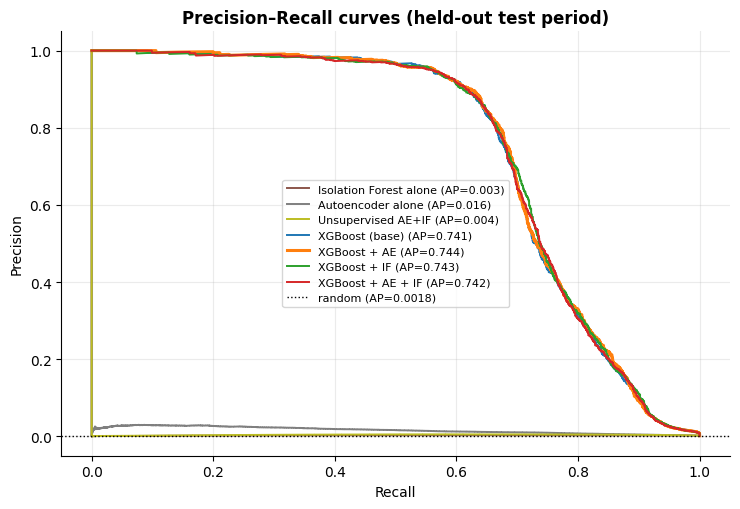

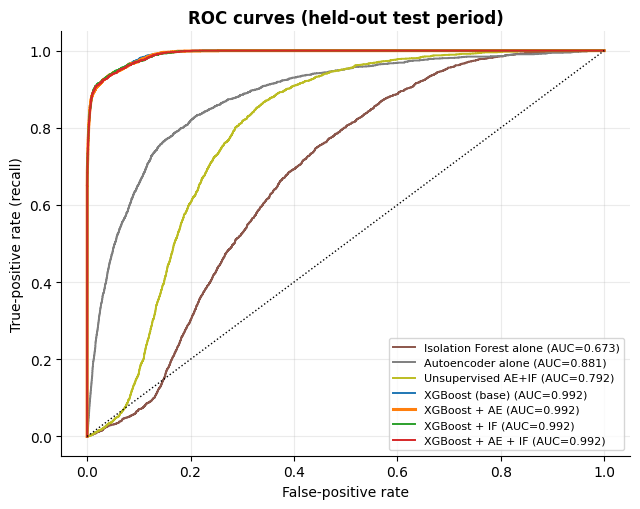

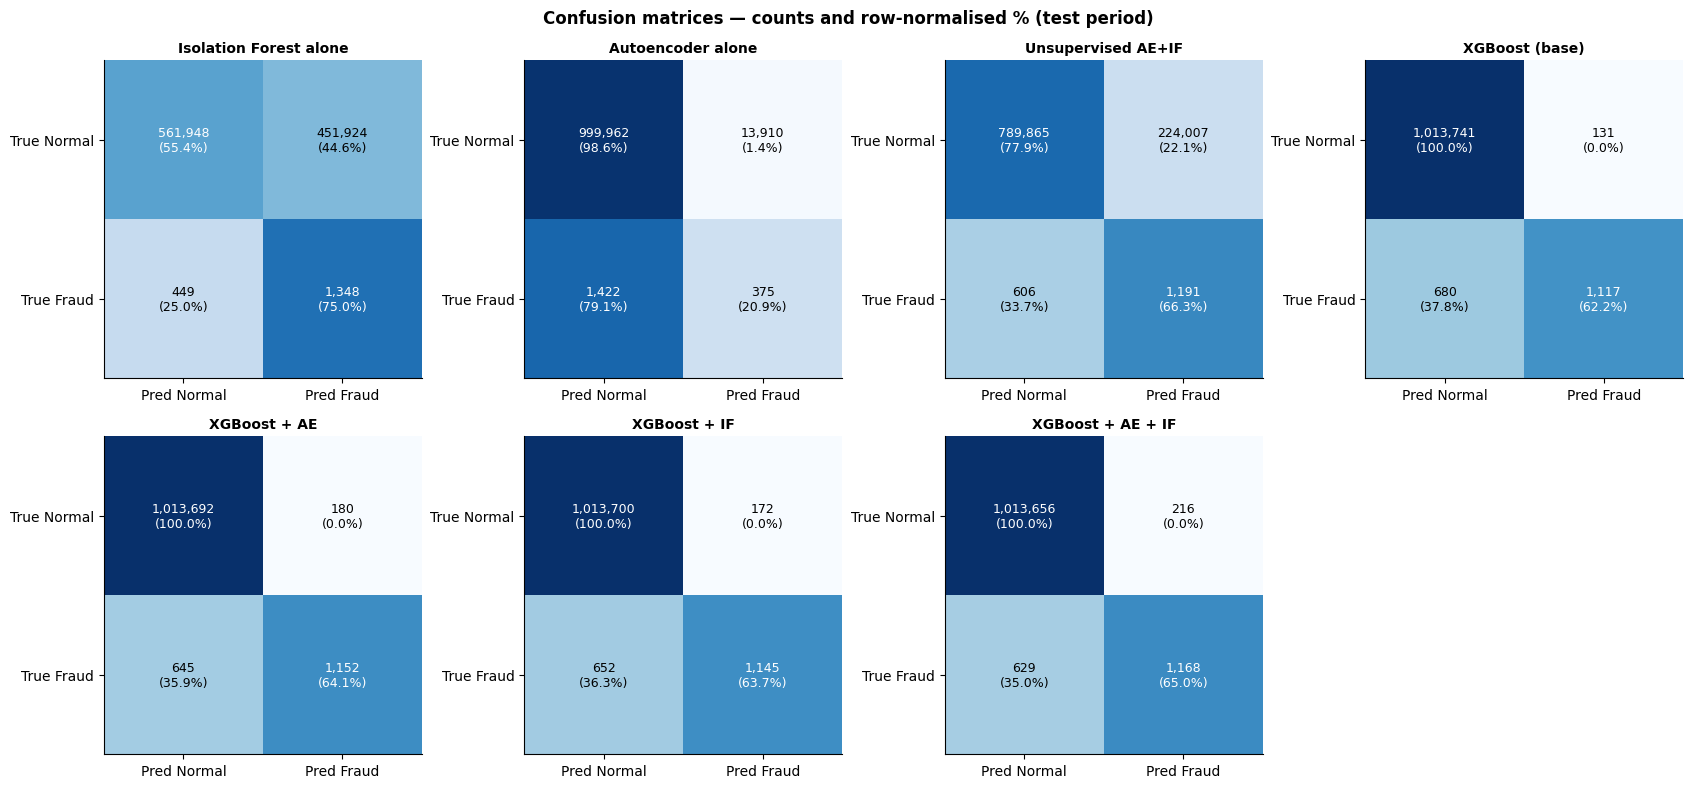

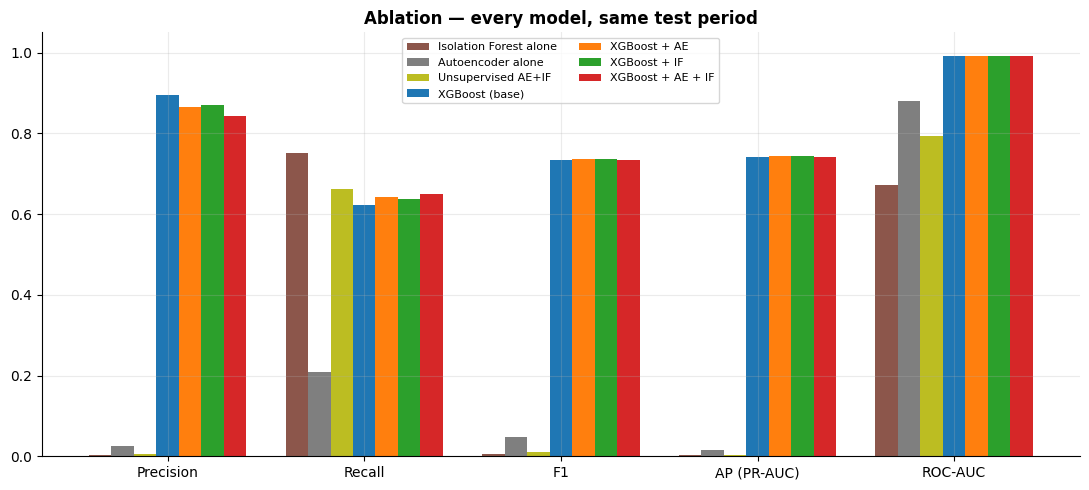

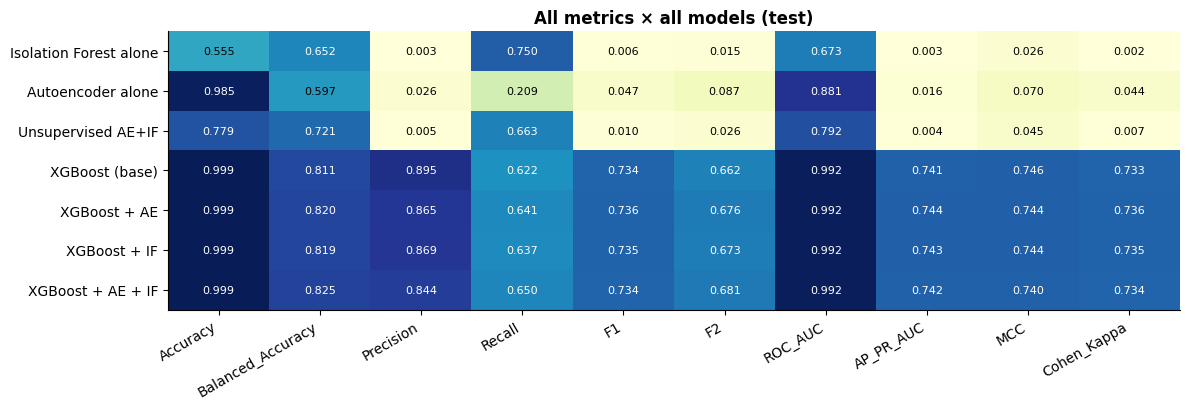

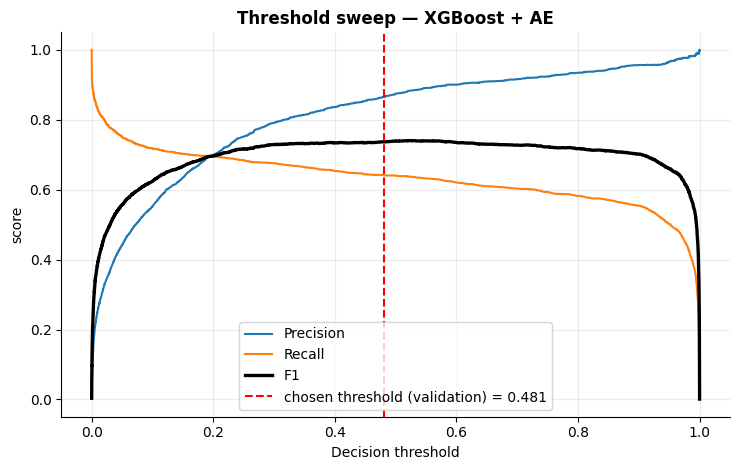

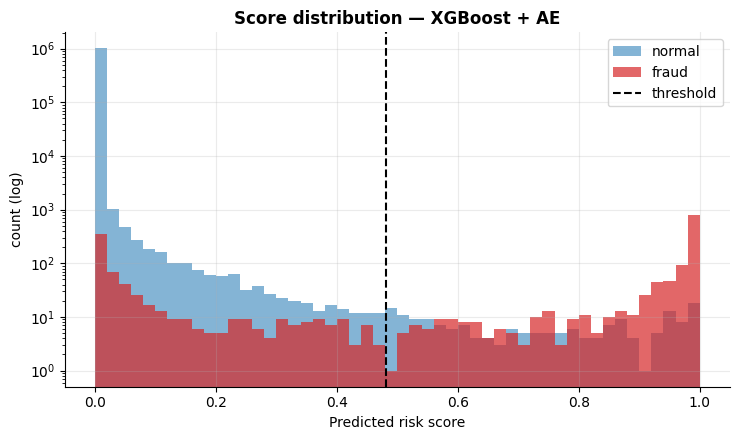

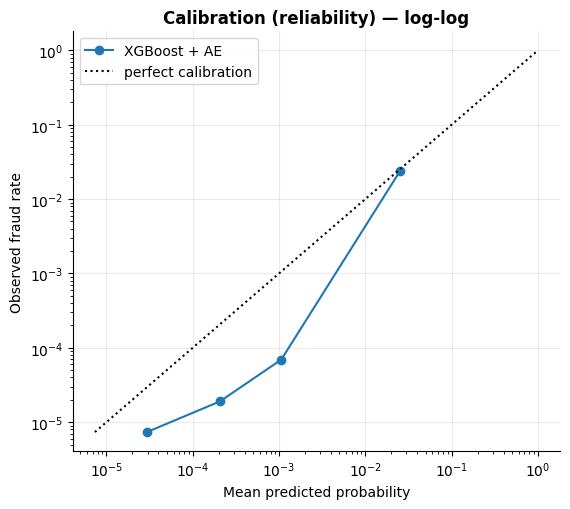

Note: scale_pos_weight>1 inflates probabilities on purpose — rank by risk score; use the validation threshold, not 0.5.


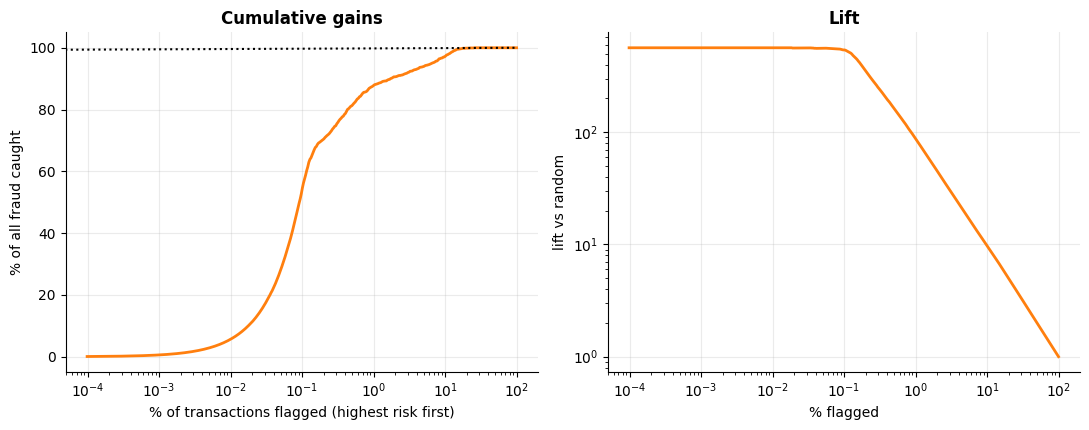

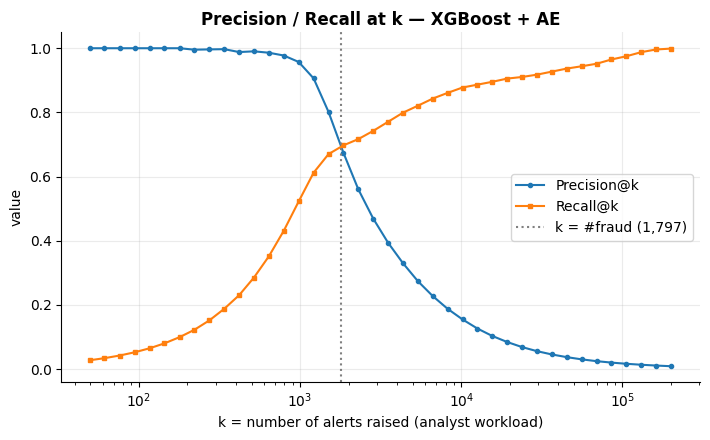

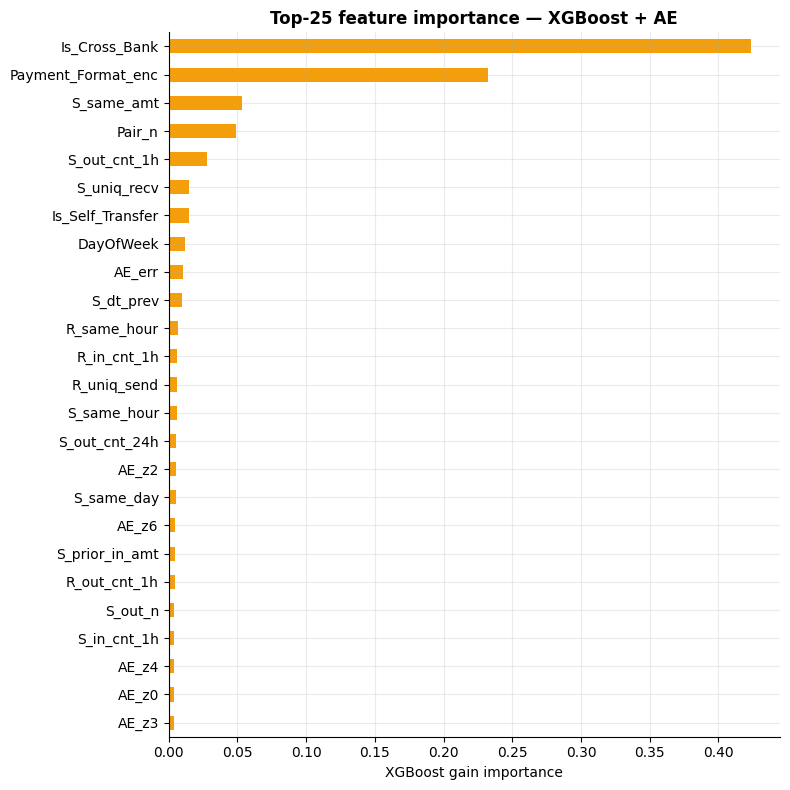

,Operating point,Threshold,Precision,Recall,F1,Alerts,TP,FP,FN
0,Best F1 (default),0.4811,0.8649,0.6411,0.7363,1332,1152,180,645
1,High precision ≥ 0.90,0.5620,0.8942,0.6305,0.7396,1267,1133,134,664
2,High recall ≥ 0.80,0.0037,0.1774,0.8687,0.2946,8800,1561,7239,236
3,High recall ≥ 0.90,0.0003,0.0425,0.9293,0.0813,39289,1670,37619,127


In [ ]:
order_ = list(V.keys())
# ---- fig04 PR curves ----
plt.figure(figsize=(7.5, 5.2))
for k in order_:
    p_, r_, _ = precision_recall_curve(y_te, V[k]['te']); plt.plot(r_, p_, color=COLORS[k], lw=2.2 if k==FINAL else 1.4, label=f"{k} (AP={average_precision_score(y_te, V[k]['te']):.3f})")
plt.axhline(y_te.mean(), color='k', ls=':', lw=1, label=f'random (AP={y_te.mean():.4f})')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision–Recall curves (held-out test period)'); plt.legend(fontsize=8); save_fig('fig04_precision_recall_curves')
# ---- fig05 ROC curves ----
plt.figure(figsize=(6.5, 5.2))
for k in order_:
    f_, t_, _ = roc_curve(y_te, V[k]['te']); plt.plot(f_, t_, color=COLORS[k], lw=2.2 if k==FINAL else 1.4, label=f"{k} (AUC={roc_auc_score(y_te, V[k]['te']):.3f})")
plt.plot([0,1],[0,1],'k:', lw=1); plt.xlabel('False-positive rate'); plt.ylabel('True-positive rate (recall)'); plt.title('ROC curves (held-out test period)'); plt.legend(fontsize=8, loc='lower right'); save_fig('fig05_roc_curves')
# ---- fig06 confusion matrices ----
fig, axs = plt.subplots(2, 4, figsize=(17, 8)); axs = axs.ravel()
for ax, k in zip(axs, order_):
    cm = confusion_matrix(y_te, V[k]['pred'], labels=[0,1]); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{cm[i,j]:,}\n({cmn[i,j]*100:.1f}%)", ha='center', va='center', color='white' if cmn[i,j] > .5 else 'black', fontsize=9)
    ax.set_xticks([0,1]); ax.set_xticklabels(['Pred Normal','Pred Fraud']); ax.set_yticks([0,1]); ax.set_yticklabels(['True Normal','True Fraud']); ax.set_title(k, fontsize=10)
for ax in axs[len(order_):]: ax.axis('off')
plt.suptitle('Confusion matrices — counts and row-normalised % (test period)', fontweight='bold'); save_fig('fig06_confusion_matrices')
# ---- fig07 ablation bars ----
mets = ['Precision','Recall','F1','AP_PR_AUC','ROC_AUC']
fig, ax = plt.subplots(figsize=(11, 5)); wd = .8 / len(order_)
for i, k in enumerate(order_):
    ax.bar(np.arange(len(mets)) + i*wd, [full.loc[k, m] for m in mets], wd, color=COLORS[k], label=k)
ax.set_xticks(np.arange(len(mets)) + .4 - wd/2); ax.set_xticklabels(['Precision','Recall','F1','AP (PR-AUC)','ROC-AUC']); ax.set_ylim(0, 1.05)
ax.set_title('Ablation — every model, same test period'); ax.legend(fontsize=8, ncol=2); save_fig('fig07_ablation_bar_chart')
# ---- fig08 metric heat-table ----
hm = compact[['Accuracy','Balanced_Accuracy','Precision','Recall','F1','F2','ROC_AUC','AP_PR_AUC','MCC','Cohen_Kappa']]
fig, ax = plt.subplots(figsize=(12, 4.2)); im = ax.imshow(hm.values.astype(float), cmap='YlGnBu', vmin=0, vmax=1, aspect='auto'); ax.grid(False)
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns, rotation=30, ha='right'); ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): ax.text(j, i, f"{hm.values[i,j]:.3f}", ha='center', va='center', fontsize=8, color='white' if hm.values[i,j] > .6 else 'black')
ax.set_title('All metrics × all models (test)'); save_fig('fig08_metrics_heatmap')

# ---- final-model diagnostics ----
p_, r_, t_ = precision_recall_curve(y_te, s_te); f_ = 2*p_[:-1]*r_[:-1]/(p_[:-1]+r_[:-1]+1e-12)
plt.figure(figsize=(7.5, 4.8)); plt.plot(t_, p_[:-1], label='Precision'); plt.plot(t_, r_[:-1], label='Recall'); plt.plot(t_, f_, label='F1', lw=2.4, color='k')
plt.axvline(THRESH, color='r', ls='--', label=f'chosen threshold (validation) = {THRESH:.3f}'); plt.xlabel('Decision threshold'); plt.ylabel('score'); plt.title(f'Threshold sweep — {FINAL}'); plt.legend(); save_fig('fig09_threshold_sweep')
save_table(pd.DataFrame({'threshold': t_, 'precision': p_[:-1], 'recall': r_[:-1], 'f1': f_}).iloc[::max(1, len(t_)//2000)], 'T06_threshold_sweep_final_model', index=False)

plt.figure(figsize=(7.5, 4.5)); bins = np.linspace(0, 1, 51)
plt.hist(s_te[y_te==0], bins=bins, alpha=.55, label='normal', color='#1f77b4'); plt.hist(s_te[y_te==1], bins=bins, alpha=.7, label='fraud', color='#d62728')
plt.yscale('log'); plt.axvline(THRESH, color='k', ls='--', label='threshold'); plt.xlabel('Predicted risk score'); plt.ylabel('count (log)'); plt.title(f'Score distribution — {FINAL}'); plt.legend(); save_fig('fig10_score_distribution')

fr, ob = calibration_curve(y_te, s_te, n_bins=15, strategy='quantile'); ok_ = (fr > 0) & (ob > 0)
plt.figure(figsize=(5.8, 5.2)); plt.loglog(fr[ok_], ob[ok_], 'o-', label=FINAL); lo_ = min(fr[ok_].min(), ob[ok_].min()); plt.loglog([lo_, 1], [lo_, 1], 'k:', label='perfect calibration')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed fraud rate'); plt.title('Calibration (reliability) — log-log'); plt.legend(); save_fig('fig11_calibration')
print("Note: scale_pos_weight>1 inflates probabilities on purpose — rank by risk score; use the validation threshold, not 0.5.")

order_s = np.argsort(-s_te); cum = np.cumsum(y_te[order_s]) / y_te.sum(); frac = np.arange(1, len(s_te)+1) / len(s_te)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4)); sel_ = np.unique(np.geomspace(1, len(s_te), 400).astype(int)) - 1
axs[0].plot(frac[sel_]*100, cum[sel_]*100, color=COLORS[FINAL], lw=2); axs[0].plot([0, 100], [0, 100], 'k:'); axs[0].set_xscale('log'); axs[0].set_xlabel('% of transactions flagged (highest risk first)'); axs[0].set_ylabel('% of all fraud caught'); axs[0].set_title('Cumulative gains')
axs[1].plot(frac[sel_]*100, (cum[sel_]/frac[sel_]), color=COLORS[FINAL], lw=2); axs[1].set_xscale('log'); axs[1].set_yscale('log'); axs[1].set_xlabel('% flagged'); axs[1].set_ylabel('lift vs random'); axs[1].set_title('Lift'); save_fig('fig12_gains_and_lift')

ks = np.unique(np.geomspace(50, min(200_000, len(s_te)), 40).astype(int)); prec_k = [y_te[order_s[:k]].mean() for k in ks]; rec_k = [y_te[order_s[:k]].sum()/y_te.sum() for k in ks]
plt.figure(figsize=(7.2, 4.5)); plt.semilogx(ks, prec_k, 'o-', ms=3, label='Precision@k'); plt.semilogx(ks, rec_k, 's-', ms=3, label='Recall@k'); plt.axvline(int(y_te.sum()), color='gray', ls=':', label=f'k = #fraud ({int(y_te.sum()):,})')
plt.xlabel('k = number of alerts raised (analyst workload)'); plt.ylabel('value'); plt.title(f'Precision / Recall at k — {FINAL}'); plt.legend(); save_fig('fig13_precision_recall_at_k')
save_table(pd.DataFrame({'k': ks, 'precision_at_k': prec_k, 'recall_at_k': rec_k}), 'T07_precision_recall_at_k', index=False)

imp = pd.Series(model.feature_importances_, index=cols_final).sort_values()
plt.figure(figsize=(8, 8)); imp.tail(25).plot.barh(color='#f59e0b'); plt.xlabel('XGBoost gain importance'); plt.title(f'Top-25 feature importance — {FINAL}'); save_fig('fig14_xgboost_feature_importance')
save_table(imp.sort_values(ascending=False).rename('gain_importance').to_frame(), 'T08_feature_importance')

# ---- operating points (thresholds picked on VALIDATION) ----
rows_ = []
for lab, kind, tgt in [('Best F1 (default)', 'f1', None), ('High precision ≥ 0.90', 'precision', .90), ('High recall ≥ 0.80', 'recall', .80), ('High recall ≥ 0.90', 'recall', .90)]:
    pv, rv, tv = precision_recall_curve(y_va, s_va)
    if kind == 'f1': th = THRESH
    elif kind == 'precision': ix = np.where(pv[:-1] >= tgt)[0]; th = tv[ix[0]] if len(ix) else None
    else: ix = np.where(rv[:-1] >= tgt)[0]; th = tv[ix[-1]] if len(ix) else None
    if th is None: rows_.append({'Operating point': lab, 'Threshold': np.nan}); continue
    pr_ = (s_te >= th).astype(int); tn_, fp_, fn_, tp_ = confusion_matrix(y_te, pr_, labels=[0,1]).ravel()
    rows_.append({'Operating point': lab, 'Threshold': th, 'Precision': precision_score(y_te, pr_, zero_division=0), 'Recall': recall_score(y_te, pr_), 'F1': f1_score(y_te, pr_), 'Alerts': int(tp_+fp_), 'TP': int(tp_), 'FP': int(fp_), 'FN': int(fn_)})
ops = pd.DataFrame(rows_); display(ops.round(4)); save_table(ops, 'T09_operating_points_final_model', index=False)

## 🔍 Step 6 — SHAP explainability (global + one-transaction explanation)
XGBoost's exact TreeSHAP (`pred_contribs=True`); all test fraud rows up to 1,000 plus 4,000 random normals.

SHAP values: (5000, 56)


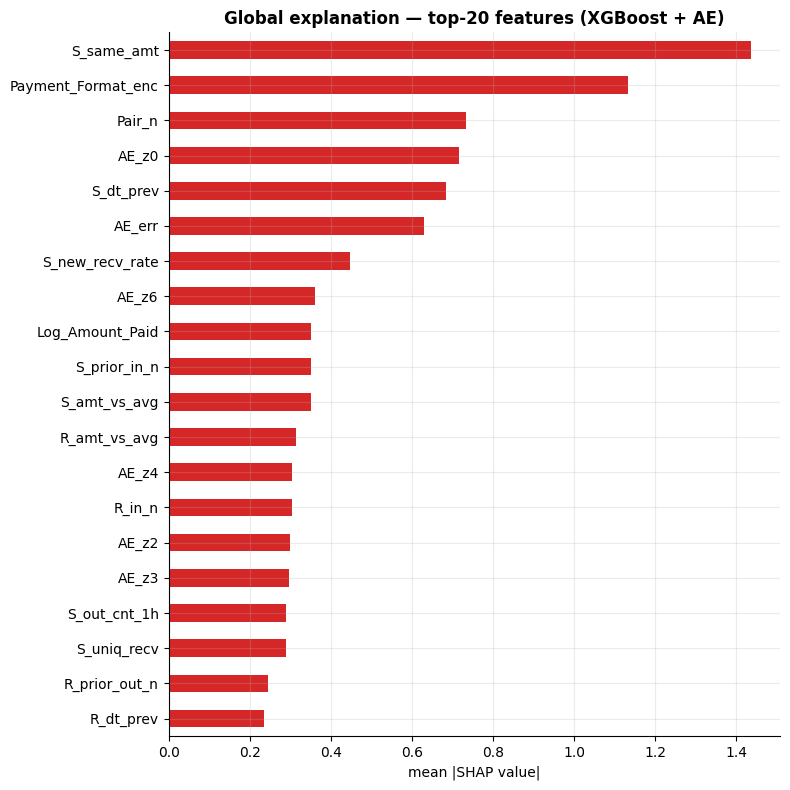

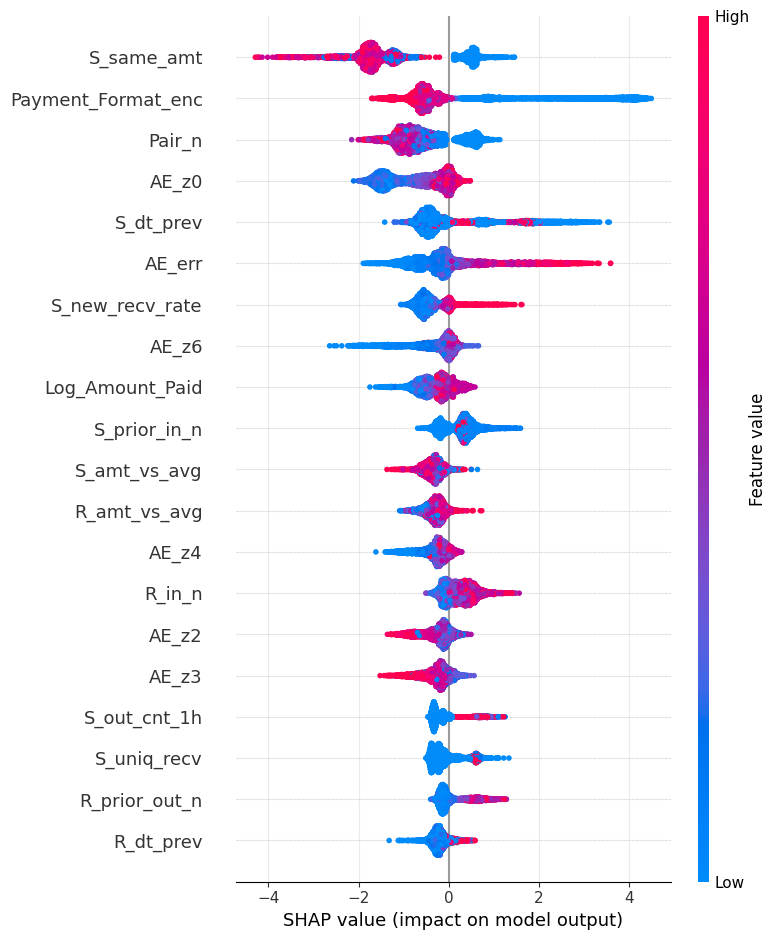

Explaining a correctly flagged laundering transaction (risk score 1.000)


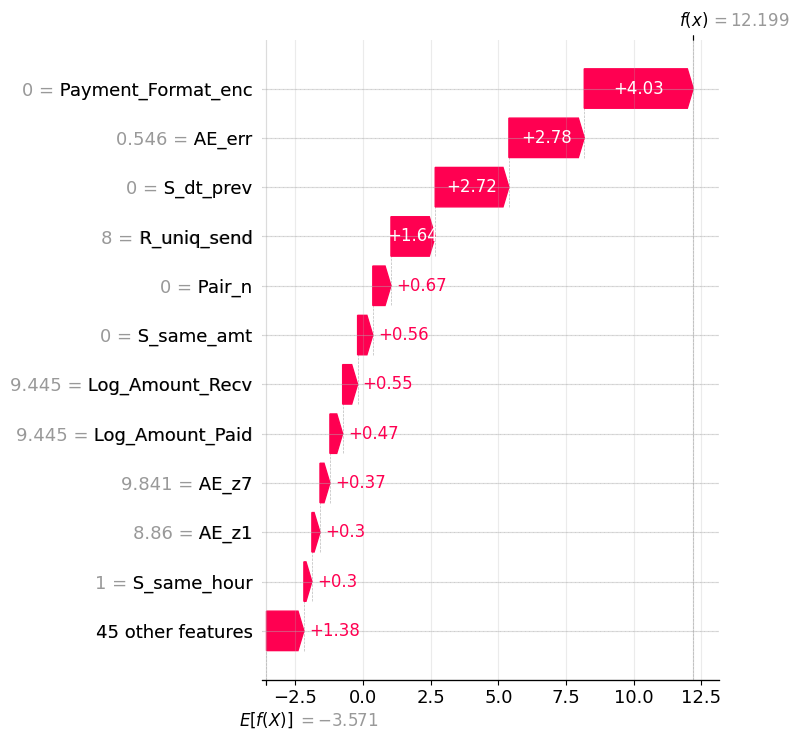

,feature,value,shap
10,Payment_Format_enc,0.000000,4.027254
47,AE_err,0.545623,2.784654
15,S_dt_prev,0.000000,2.723244
24,R_uniq_send,8.000000,1.635199
16,Pair_n,0.000000,0.670893
21,S_same_amt,0.000000,0.561787
1,Log_Amount_Recv,9.444839,0.552527
0,Log_Amount_Paid,9.444839,0.470642
55,AE_z7,9.840512,0.366642
49,AE_z1,8.860172,0.299663


In [ ]:
import shap
rs = np.random.default_rng(1)
fi = rs.choice(np.where(y_te==1)[0], min(1000, int(y_te.sum())), replace=False)
ni = rs.choice(np.where(y_te==0)[0], min(4000, int((y_te==0).sum())), replace=False)
sel = np.concatenate([fi, ni]); Xs = X_te_f[sel]; ys = y_te[sel]
contribs = model.get_booster().predict(xgb.DMatrix(Xs), pred_contribs=True)
sv, base = contribs[:, :-1], contribs[:, -1]; print("SHAP values:", sv.shape)
shap_imp = pd.Series(np.abs(sv).mean(0), index=cols_final).sort_values(ascending=False); save_table(shap_imp.rename('mean_abs_shap').to_frame(), 'T10_shap_importance')
plt.figure(figsize=(8, 8)); shap_imp.head(20)[::-1].plot.barh(color='#d62728'); plt.xlabel('mean |SHAP value|'); plt.title(f'Global explanation — top-20 features ({FINAL})'); save_fig('fig15_shap_bar')
try:
    shap.summary_plot(sv, Xs, feature_names=cols_final, max_display=20, show=False); save_fig('fig16_shap_beeswarm')
except Exception as e: print("beeswarm skipped:", e)
sc = model.predict_proba(Xs)[:, 1]; cand = np.where((ys==1) & (sc >= THRESH))[0]
if len(cand):
    j = cand[np.argmax(sc[cand])]; print(f"Explaining a correctly flagged laundering transaction (risk score {sc[j]:.3f})")
    try:
        shap.plots.waterfall(shap.Explanation(values=sv[j], base_values=base[j], data=Xs[j], feature_names=cols_final), max_display=12, show=False); save_fig('fig17_shap_waterfall_single_transaction')
    except Exception as e: print("waterfall skipped:", e)
    top_ = pd.DataFrame({'feature': cols_final, 'value': Xs[j], 'shap': sv[j]}).reindex(np.argsort(-np.abs(sv[j]))[:12]); display(top_); save_table(top_, 'T11_single_transaction_explanation', index=False)

## 🔁 Step 7 — Refit the final model on train + validation (clearly-labelled second result)
Validation is closer in time to the test period. The threshold from Step 5 is carried over; this is **reported separately**, never mixed with the main result.

In [ ]:
best_iter = model.best_iteration + 1
params = model.get_params(); params.update(n_estimators=best_iter, early_stopping_rounds=None)
model_full = xgb.XGBClassifier(**params)
model_full.fit(np.vstack([X_tr_f, X_va_f]), np.concatenate([y_tr, y_va]), verbose=False)
s_te2 = model_full.predict_proba(X_te_f)[:, 1]; pred2 = (s_te2 >= THRESH).astype(int)
refit = pd.DataFrame([full_metrics(f'{FINAL} — refit on train+val', y_te, s_te2, THRESH, True)]).set_index('Model')
save_table(refit, 'T12_refit_train_val_metrics'); display(refit[['Accuracy','Precision','Recall','F1','ROC_AUC','AP_PR_AUC','MCC']].round(4))
r2 = classification_report(y_te, pred2, target_names=['Normal','Fraud'], digits=4, zero_division=0); print(r2)
open(f'{TAB}/classification_report_refit.txt', 'w').write(r2); SAVED.append(f'{TAB}/classification_report_refit.txt')

,Accuracy,Precision,Recall,F1,ROC_AUC,AP_PR_AUC,MCC
Model,,,,,,,
XGBoost + AE — refit on train+val,0.9993,0.8969,0.6583,0.7593,0.9925,0.7567,0.7681


              precision    recall  f1-score   support

      Normal     0.9994    0.9999    0.9996   1013872
       Fraud     0.8969    0.6583    0.7593      1797

    accuracy                         0.9993   1015669
   macro avg     0.9481    0.8291    0.8795   1015669
weighted avg     0.9992    0.9993    0.9992   1015669



## 💾 Step 8 — Save everything (models, tables, figures, summary) + zip + Drive copy

In [ ]:
model.save_model(f'{MOD}/xgboost_final.json'); model_full.save_model(f'{MOD}/xgboost_final_trainval.json')
torch.save(ae.state_dict(), f'{MOD}/autoencoder.pt')
joblib.dump({'med': AE_MED, 'mu': AE_MU, 'sd': AE_SD}, f'{MOD}/ae_prep.pkl')
joblib.dump(iforest, f'{MOD}/isolation_forest.pkl')
joblib.dump({'base_features': feature_cols, 'final_features': cols_final, 'uses_ae': 'AE_err' in cols_final, 'uses_if': 'IF_score' in cols_final}, f'{MOD}/feature_cols.pkl')
fm = full.loc[FINAL]
meta = {'final_variant': FINAL, 'threshold': THRESH, 'config(depth,spw,mcw)': best_cfg, 'n_features': len(cols_final),
        'dataset': 'IBM AML HI-Small (time-split 60/20/20)', 'test_rows': int(len(y_te)), 'test_fraud': int(y_te.sum()),
        'test_metrics': {k: (None if pd.isna(v) else float(v)) for k, v in fm.items() if k != 'Threshold'},
        'refit_train_val_metrics': {k: float(v) for k, v in refit.iloc[0].items() if k in ['Precision','Recall','F1','ROC_AUC','AP_PR_AUC','Accuracy','MCC']},
        'all_models': {k: {m: (None if pd.isna(full.loc[k, m]) else float(full.loc[k, m])) for m in ['Accuracy','Precision','Recall','F1','ROC_AUC','AP_PR_AUC','MCC']} for k in full.index}}
json.dump(meta, open(f'{OUT}/metadata.json', 'w'), indent=2); shutil.copy(f'{OUT}/metadata.json', f'{MOD}/metadata.json')

summary = f'''# DeepGuard — training results summary

Final model (chosen on validation AP): **{FINAL}**  | threshold {THRESH:.4f} (best F1 on validation)

## Test-set metrics, all models
```
{compact.round(4).to_string()}
```
## Confusion counts
```
{full[['TP','FP','FN','TN','FPR','FNR','Alerts']].round(5).to_string()}
```
## Bootstrap 95% CI
```
{ci.round(4).to_string()}
```
## Operating points (final model)
```
{ops.round(4).to_string(index=False)}
```
Notes: fraud is {y_te.mean()*100:.3f}% of the test period, so Accuracy is not informative — judge AP, ROC-AUC, Precision, Recall, F1, MCC.
'''
open(f'{OUT}/RESULTS_SUMMARY.md', 'w').write(summary)

zpath = f'{ROOT}/DeepGuard_Training_Results.zip'
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for dp, _, fs in os.walk(OUT):
        for f in fs: z.write(os.path.join(dp, f), os.path.relpath(os.path.join(dp, f), OUT))
try:
    from google.colab import drive; drive.mount('/content/drive')
    shutil.copytree(OUT, '/content/drive/MyDrive/DeepGuard/training_results_final', dirs_exist_ok=True)
    print('✅ copied to Drive → MyDrive/DeepGuard/training_results_final')
except Exception as e: print('Drive copy skipped:', e)
print(f"\n📦 {len(SAVED)} figures/tables + models saved under {OUT}\n   zip: {zpath}")
for sub in (FIG, TAB, MOD): print(f"\n{os.path.basename(sub)}/"); [print('  ', f) for f in sorted(os.listdir(sub))]
try:
    from google.colab import files; files.download(zpath)
except Exception: pass

Mounted at /content/drive
✅ copied to Drive → MyDrive/DeepGuard/training_results_final

📦 32 figures/tables + models saved under /content/deepguard_results
   zip: /content/DeepGuard_Training_Results.zip

figures/
   fig01_autoencoder_training_loss.png
   fig02_autoencoder_error_drift.png
   fig03_isolation_forest_scores.png
   fig04_precision_recall_curves.png
   fig05_roc_curves.png
   fig06_confusion_matrices.png
   fig07_ablation_bar_chart.png
   fig08_metrics_heatmap.png
   fig09_threshold_sweep.png
   fig10_score_distribution.png
   fig11_calibration.png
   fig12_gains_and_lift.png
   fig13_precision_recall_at_k.png
   fig14_xgboost_feature_importance.png
   fig15_shap_bar.png
   fig16_shap_beeswarm.png
   fig17_shap_waterfall_single_transaction.png

tables/
   T00_data_split.csv
   T01_feature_bruteforce_check.csv
   T02_autoencoder_training_history.csv
   T03_all_metrics_all_models_TEST.csv
   T04_classification_reports_all_models.csv
   T05_bootstrap_95CI.csv
   T06_threshold_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 📝 How to read & present these results
* **Pick the headline numbers from the table above:** *Average Precision*, *ROC-AUC*, *Precision*, *Recall*, *F1*, *MCC* — not Accuracy (≈ 99.9 % for everything because 99.8 % of rows are normal).
* **Ablation story for the report:** Isolation Forest and the Autoencoder are *unsupervised* (no labels) and weak on their own; XGBoost with behavioural features does the heavy lifting; the paired-bootstrap ΔAP above tells you honestly whether adding AE / IF helps.
* **Threshold:** the default is the best-F1 point on validation; `T09_operating_points_final_model.csv` gives high-precision / high-recall alternatives for analysts.
* **F1 > 0.88** is not reachable on this dataset's real class imbalance without leakage — see AP, precision and recall for the honest picture.